## Charaterizing Clusters
By : Josh Navarro

### Goal for Today: 

Starting with clusters identified in the previous module, find candidate marker genes, explore their expression, and use the evidence to discuss potential cell types and states.

### Workflow:
1. Imports
2. Loading the data
3. Understanding the data
4. Differential Gene Expression
5. Cluster Gene-Level Expression
6. Cell-Type and Cell-State Characterization
7. Visualizations

### The imports that we are going to be using / downloading

- scanpy = Single-cell analysis and plots


- anndata = Read the Dataset

- pandas = Gene Tables

- numpy = calculations

- matplotlib = plot customizations

In [18]:
# Imports that we are going to use

import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sc.set_figure_params(dpi=110, frameon=False)

### Loading in the Data

Our input is an AnnData (.h5ad) file generated by the clustering module. It holds the gene-expression matrix (adata.X), cell metadata (adata.obs), gene metadata (adata.var), and dimensionality-reduction coordinates (adata.obsm).

We will load in the data that we were able to cluster last week.

In [19]:
# Will need to change the path to your own path of the data.
adata = ad.read_h5ad("C:/Users/joshu/Desktop/EAGER_scRNA-seq/data/clusteredadata.h5ad")
# Preview the data
adata

AnnData object with n_obs × n_vars = 15989 × 5000
    obs: 'AB_id', 'plate_num', 'plate_id', 'ng_per_ul', 'sorting_session', 'mouse_id', 'cyclophosphamide', 'treatment', 'experiment_type', 'gate', 'tissue', 'ratio', 'timepoint', 'replicate', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_genes', 'outlier', 'mt_outlier', '_scvi_batch', '_scvi_labels', 'leiden_0.5', 'leiden_0.8', 'leiden_1.0', 'leiden_1.5', 'leiden_scVI', 'cell_type', 'well', 'huHer2 FITC-A', 'Her2CAR APC-A', 'CD44 APC-CY7-A', 'CD4 BV510-A', 'CD62L BV605-A', '4-1BB PE-A', 'CD69 PE-Cy7-A', 'live_dead DAPI-A', 'CD8a BUV805-A', 'CD4 FITC-A', 'CD107a BV421-A', 'PD1 BV510-A', 'H

### Understanding the Clustered Data

Each row represents a cell and each column represents a gene. The leiden column stores the previously identified cluster labels. A UMAP is a two-dimensional visual summary of cell similarity; nearby points are often transcriptionally similar, but distances on the plot should not be treated as precise biological distances.

In [20]:
# Check the data 
print("Cells and genes:", adata.shape)
print("Number of clusters:", adata.obs["leiden"].nunique())
print(adata.obs["leiden"].value_counts().sort_index())
print("Available embeddings:", list(adata.obsm.keys()))

Cells and genes: (15989, 5000)
Number of clusters: 13
leiden
0     1198
1     1738
2      859
3     3359
4     1250
5     2005
6      722
7      809
8     1993
9      929
10     888
11      52
12     187
Name: count, dtype: int64
Available embeddings: ['X_pca', 'X_scVI', 'X_umap', 'X_umap_pca', 'X_umap_scvi']


### Vizulize the previously identified clusters.

In [21]:
print(adata.obsm.keys())
print(adata.obs["leiden"].value_counts())

KeysView(AxisArrays with keys: X_pca, X_scVI, X_umap, X_umap_pca, X_umap_scvi)
leiden
3     3359
5     2005
8     1993
1     1738
4     1250
0     1198
9      929
10     888
2      859
7      809
6      722
12     187
11      52
Name: count, dtype: int64


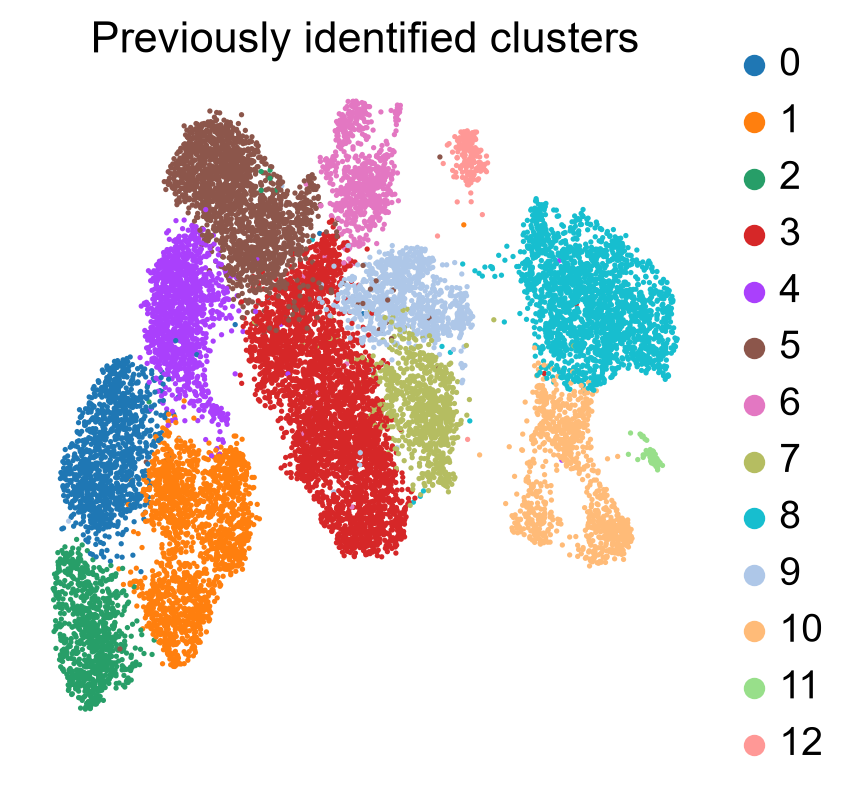

In [22]:
sc.pl.umap(
    adata,
    color="leiden",
    legend_loc="right margin",
    title="Previously identified clusters",
    size=12
)

Think about it: Which clusters contain the most cells? Can distinct-looking UMAP groups still share the same broad cell type?
Data check before differential expression: The notebook contains counts and scvi_normalized layers. For Wilcoxon differential expression, use a suitable normalized, log-transformed gene-expression matrix—not raw counts, scaled values, or a latent embedding. The code below uses adata.X (use_raw=False), so confirm its contents in the previous preprocessing module first. Do not assume the layer named scvi_normalized is log-transformed

In [23]:
print("Layers:", list(adata.layers.keys()))
print("Has raw matrix:", adata.raw is not None)
print("Preprocessing log1p metadata:", adata.uns.get("log1p"))

Layers: ['counts', 'scvi_normalized']
Has raw matrix: True
Preprocessing log1p metadata: {}


### Differential Gene Expression

Question: Which genes distinguish one cluster from the others?

We apply the Wilcoxon rank-sum test, comparing cells in each Leiden cluster against cells in all other clusters. The output is a ranked list of candidate markers—not a list of proven cell-type markers.
- Adjusted p-value (pvals_adj) accounts for testing many genes.
- Log fold change (logfoldchanges) approximates the magnitude and direction of the expression difference.
- A positive log fold change means higher expression in the chosen cluster relative to the reference group.
Important: Only run this cell after confirming adata.X is appropriate log-normalized expression. If it is not, prepare a suitable matrix first; do not run DE on raw counts or scVI latent coordinates.


In [24]:
# Rank by the gene expression
sc.tl.rank_genes_groups(
    adata,
    groupby="leiden",
    method="wilcoxon",
    use_raw=False
)

In [25]:
# Initilize the dataframe 
deg = sc.get.rank_genes_groups_df(
    adata,
    group="0"
)

# Outputs the top 10 expressed genes
deg.head(10)

,names,scores,logfoldchanges,pvals,pvals_adj
0,Gm12250,33.349846,2.912807,7.321910e-244,3.660955e-240
1,Igtp,32.667145,2.737193,4.575137e-234,1.143784e-230
2,Ltb,32.044315,2.134461,2.634500e-225,4.390833e-222
3,Gzmb,28.878733,2.523075,2.208699e-183,2.208699e-180
4,Il2ra,27.792923,2.317021,5.282196e-170,4.401830e-167
5,Il12rb2,27.394793,2.681791,3.163639e-165,2.259742e-162
6,Mir6974,26.821579,3.008818,1.810311e-158,1.131444e-155
7,Ifi47,24.920528,1.874199,4.458026e-137,2.476681e-134
8,Irgm1,24.678734,2.232623,1.809519e-134,9.047597e-132
9,Iigp1,24.579344,2.818916,2.101006e-133,9.550027e-131


For a simple teaching shortlist, keep genes with an adjusted p-value below 0.05 and log2 fold change above 1. These cutoffs are illustrative, not universal biological rules. Highly significant genes are not necessarily specific to one cell type.

In [26]:
significant_genes = deg[
    (deg["pvals_adj"] < 0.05) &
    (deg["logfoldchanges"] > 1)
]

significant_genes[["names", "logfoldchanges", "pvals_adj"]].head(10)


,names,logfoldchanges,pvals_adj
0,Gm12250,2.912807,3.660955e-240
1,Igtp,2.737193,1.143784e-230
2,Ltb,2.134461,4.390833e-222
3,Gzmb,2.523075,2.208699e-180
4,Il2ra,2.317021,4.401830e-167
5,Il12rb2,2.681791,2.259742e-162
6,Mir6974,3.008818,1.131444e-155
7,Ifi47,1.874199,2.476681e-134
8,Irgm1,2.232623,9.047597e-132
9,Iigp1,2.818916,9.550027e-131


### Cluster Gene-Level Expression

Question: Where are the top candidate markers expressed?

A dot plot compares expression across clusters. Dot size shows the fraction of cells with detectable expression; dot color shows mean expression. This helps distinguish markers restricted to a cluster from genes expressed broadly.

In [27]:
marker_genes = significant_genes["names"].head(5).tolist()

print("Candidate markers for cluster 0: ", marker_genes)

Candidate markers for cluster 0:  ['Gm12250', 'Igtp', 'Ltb', 'Gzmb', 'Il2ra']


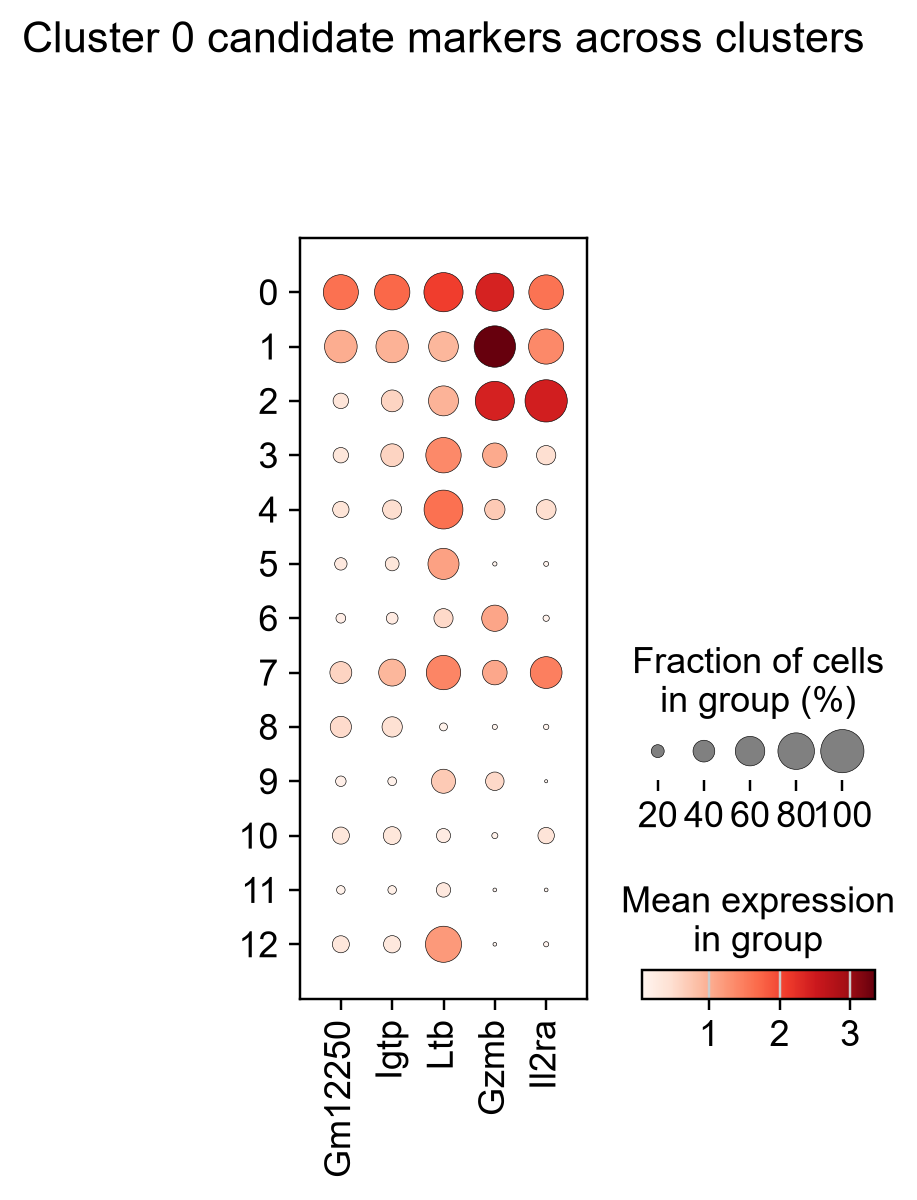

In [28]:
sc.pl.dotplot(
    adata,
    var_names=marker_genes,
    groupby="leiden",
    title="Cluster 0 candidate markers across clusters"
)

### Cell-Type and Cell-State Characterization

Cell type describes a cell's identity (for example, a T cell). Cell state describes its current biological condition (for example, activated or proliferating).

Differential expression suggests candidate markers, but we need multiple supporting genes, known biological markers, and independent metadata before assigning an identity. Our dataset already includes cell_type_v2, which we can compare against cluster labels; those annotations are supporting information, not automatic ground truth.

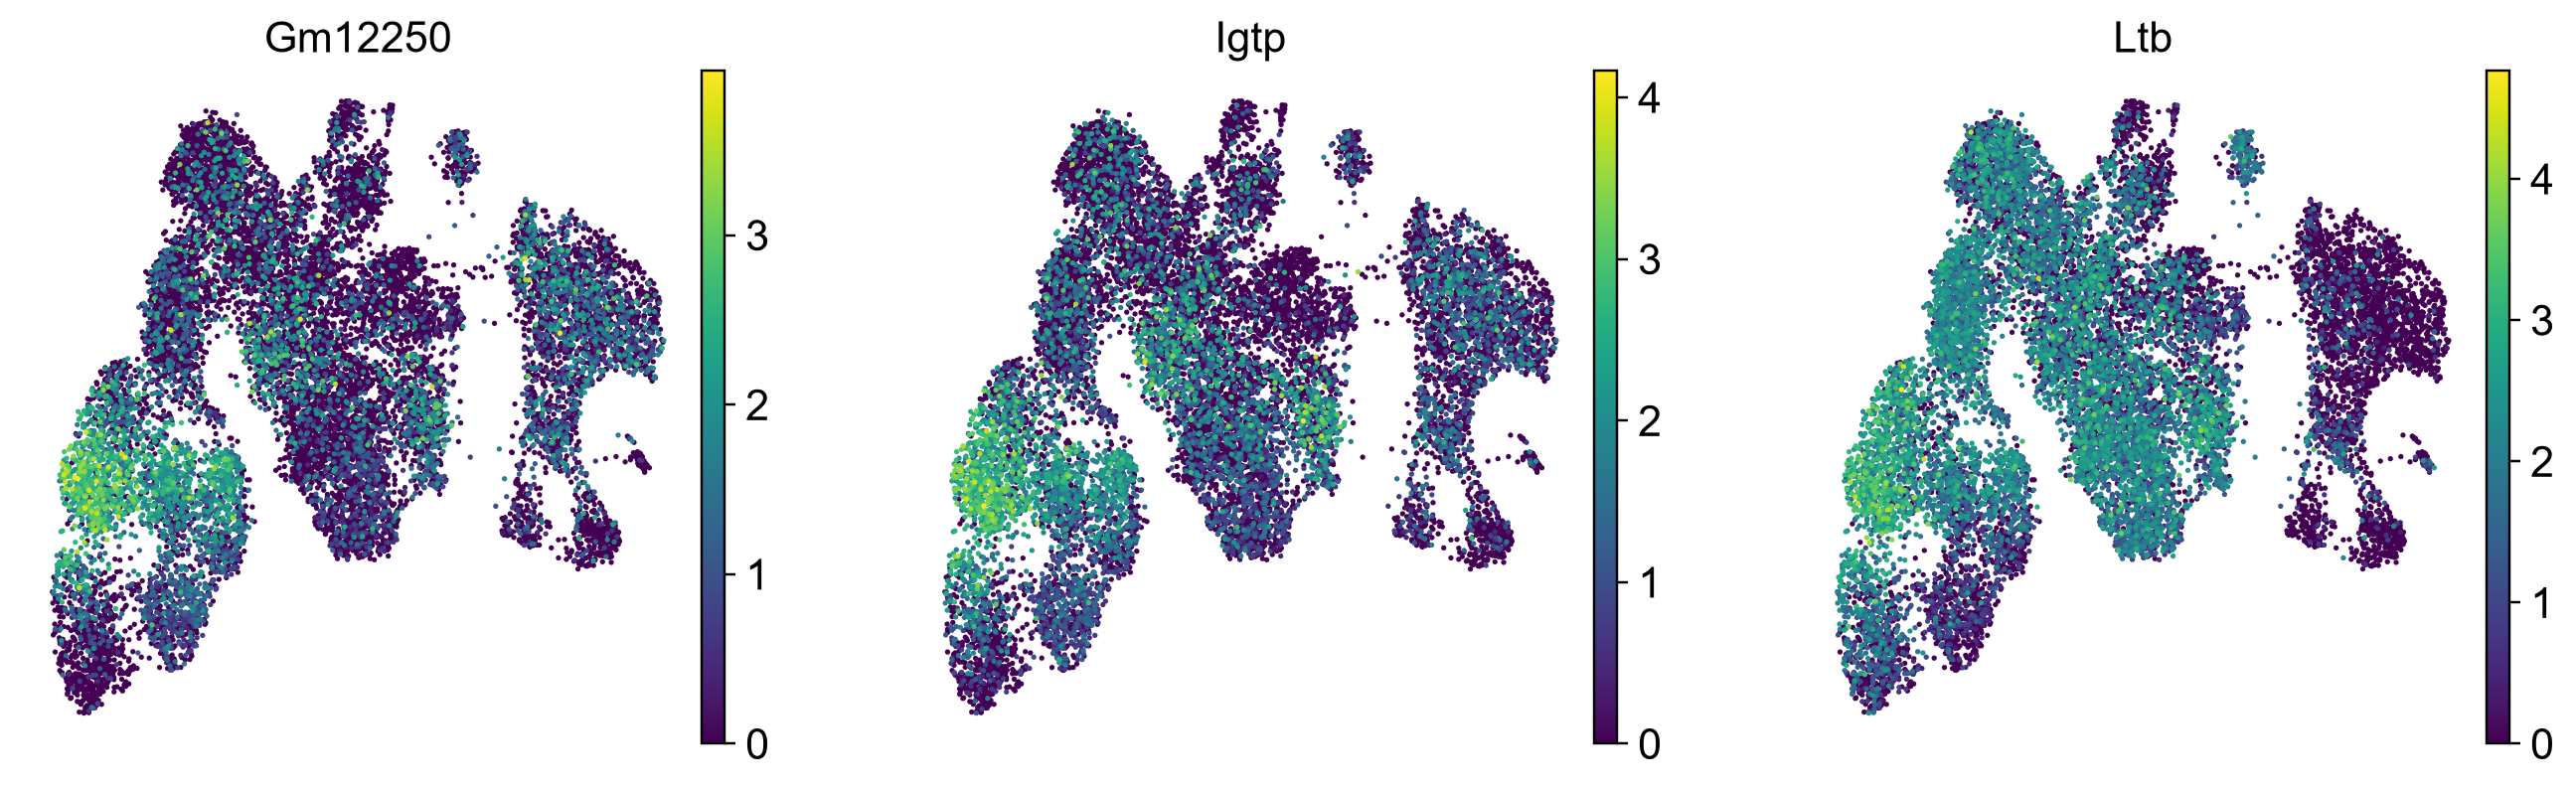

In [29]:
sc.pl.umap(
    adata,
    color=marker_genes[:3],
    ncols=3,
    size=12,
    cmap="viridis"
)

In [30]:
pd.crosstab(
    adata.obs["leiden"],
    adata.obs["cell_type_v2"],
    normalize="index"
).round(2)

cell_type_v2,Tnaive,Tscm,Tcm,Teff_early,Teff,Tpex,Tpex_int,Tpex_cycling,Tex_cycling,Tterm,...,Treg,NK,NK_act,TAM_homeo,TAM_inflam,cDC1,cDC2,mDC_Ccr7,pDC,Bcell
leiden,,,,,,,,,,,,,,,,,,,,,
0,0.00,0.01,0.00,0.90,0.05,0.02,0.00,0.01,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,0.00,0.01,0.00,0.03,0.25,0.01,0.00,0.36,0.00,0.34,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2,0.00,0.00,0.00,0.00,0.00,0.98,0.00,0.00,0.00,0.01,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
3,0.00,0.00,0.01,0.00,0.31,0.02,0.00,0.00,0.20,0.44,...,0.00,0.01,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
4,0.02,0.86,0.02,0.02,0.02,0.00,0.00,0.05,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
5,0.52,0.03,0.37,0.01,0.03,0.02,0.00,0.00,0.00,0.00,...,0.00,0.00,0.02,0.00,0.00,0.00,0.00,0.00,0.00,0.00
6,0.00,0.00,0.02,0.00,0.03,0.01,0.00,0.00,0.00,0.02,...,0.00,0.62,0.30,0.00,0.00,0.00,0.00,0.00,0.00,0.00
7,0.04,0.00,0.00,0.00,0.01,0.01,0.00,0.00,0.01,0.04,...,0.76,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
8,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.01,0.00,0.88,0.07,0.00,0.02,0.00,0.00,0.00


### Visualization

Each visualization answers a different question. Use the ranked-gene plot to find top candidates, the heatmap to compare patterns across clusters, and the volcano plot to compare effect size with statistical evidence.

1. Top-Ranked Genes

The score reflects the differential expression test statistic. A high score does not automatically mean a large fold change

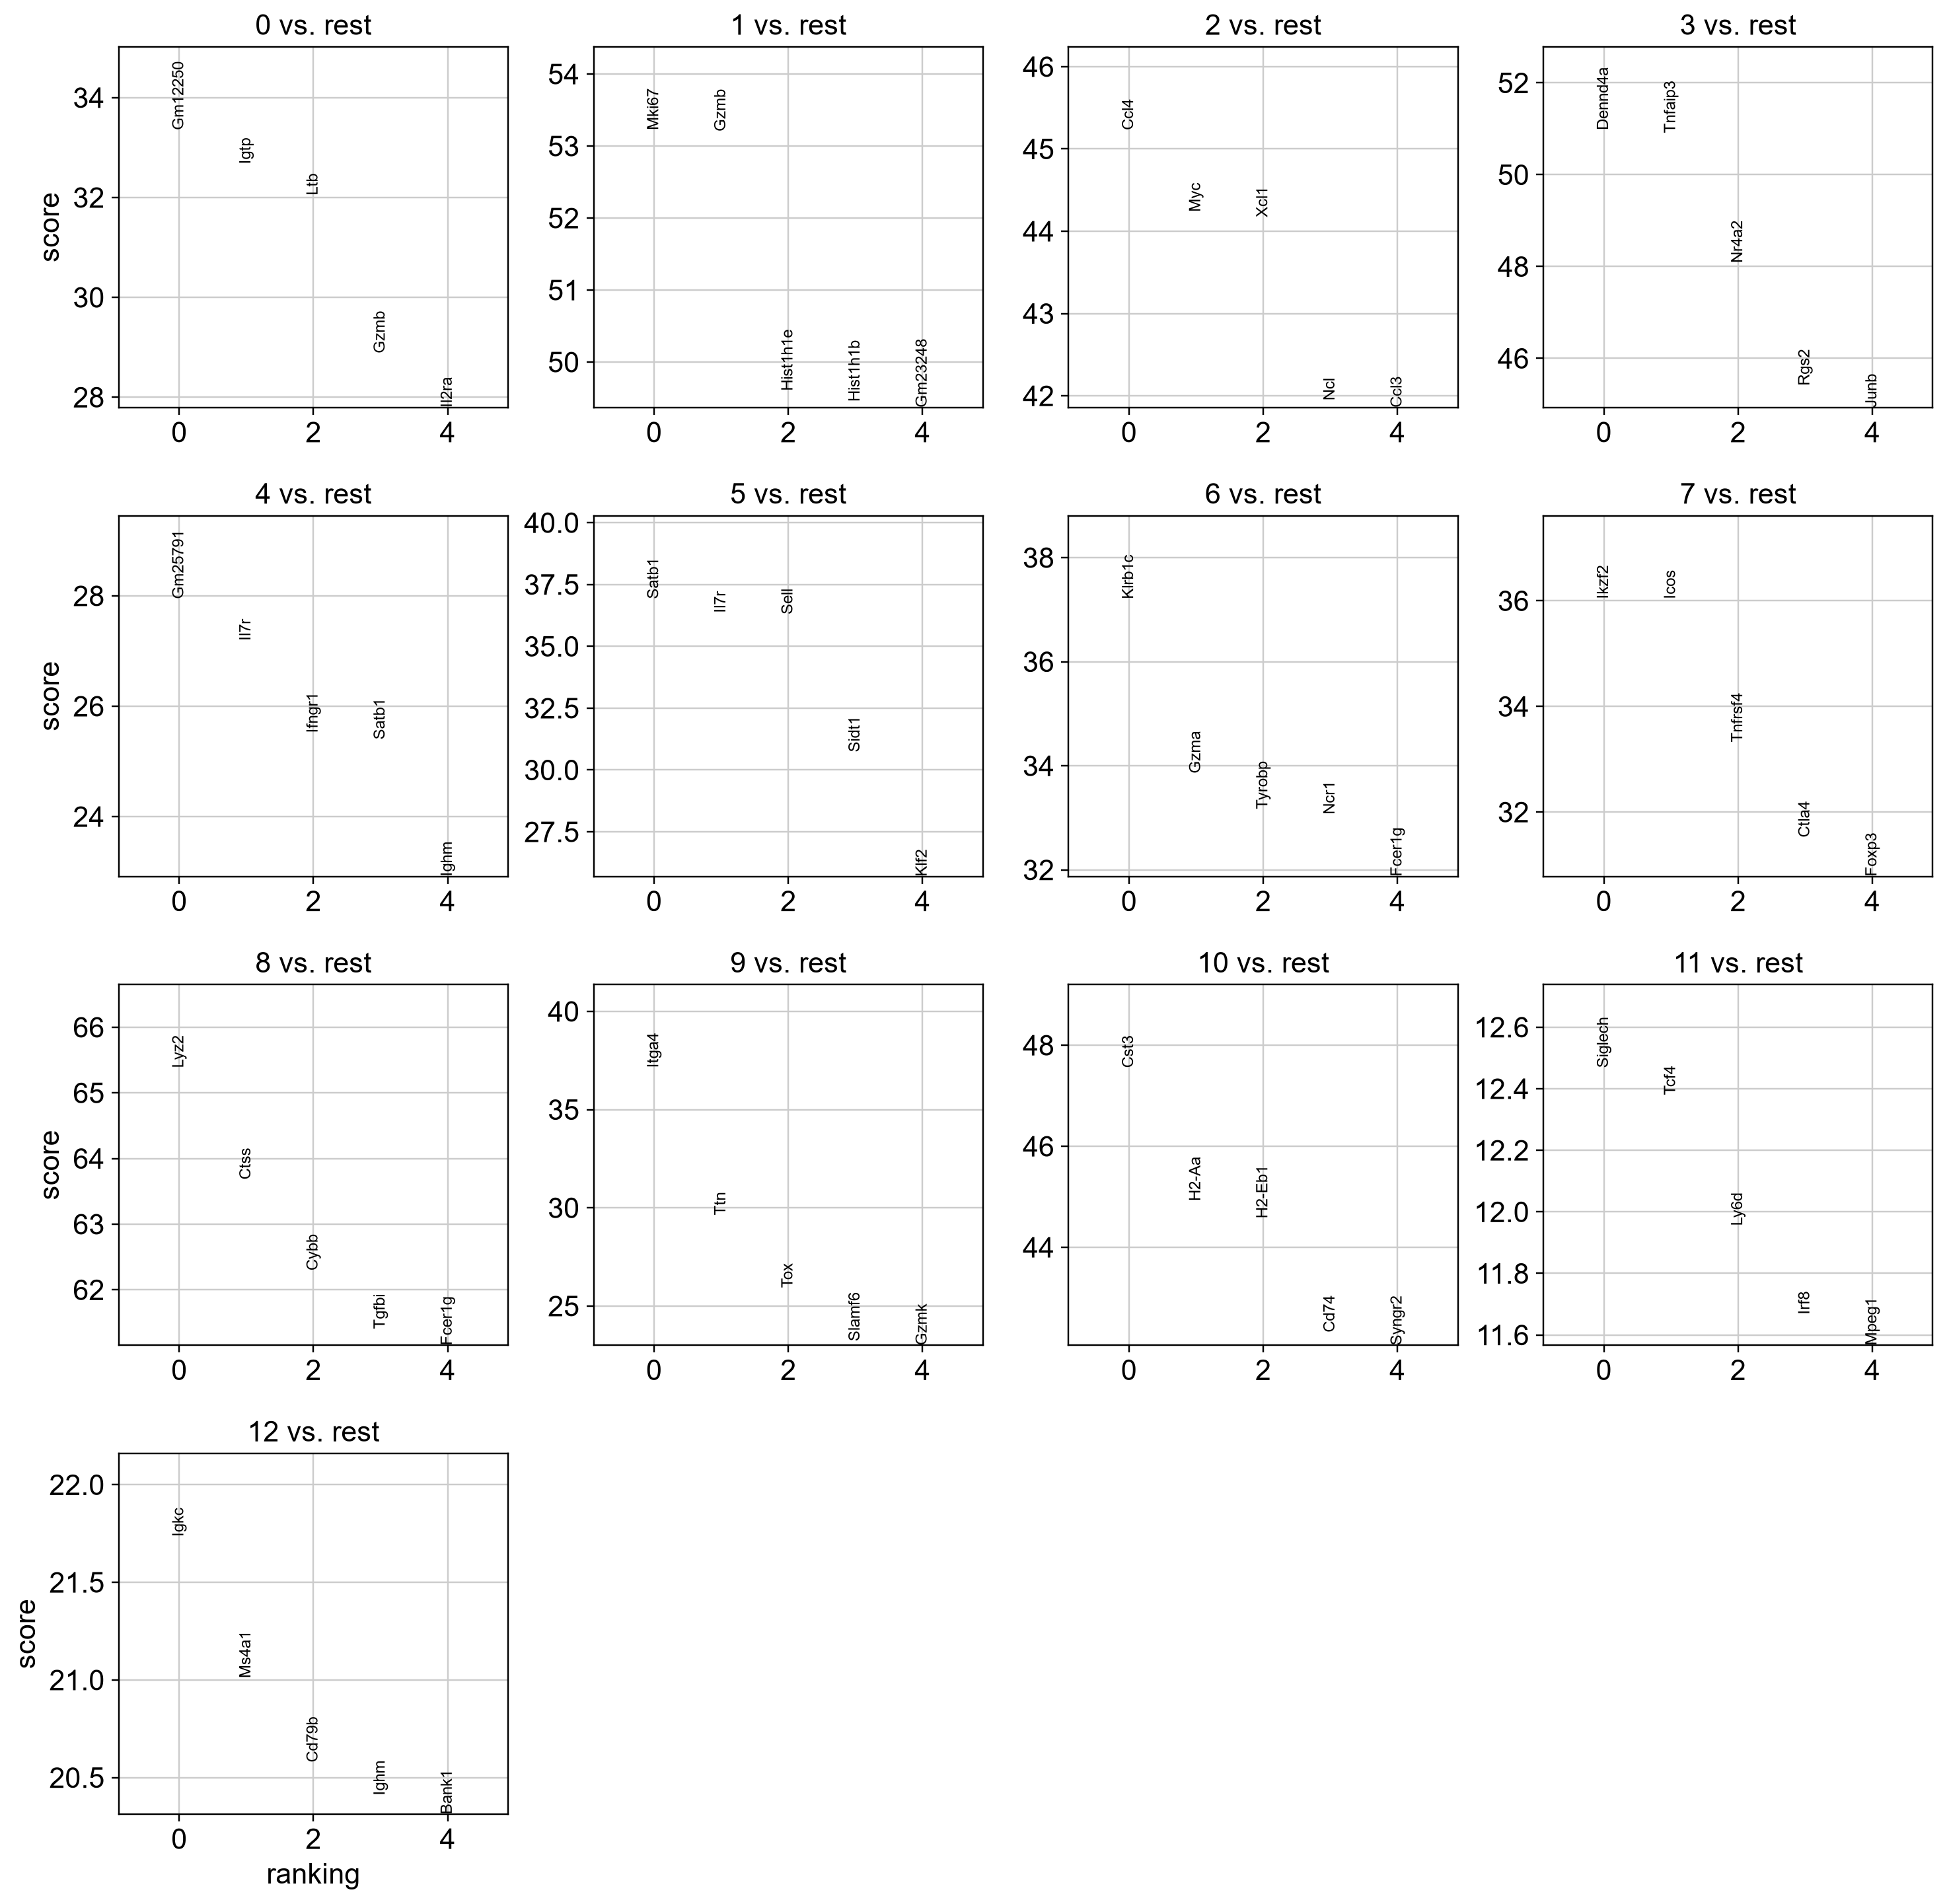

In [31]:
sc.pl.rank_genes_groups(
    adata,
    n_genes=5,
    sharey=False
)

2. Heatmap
The heatmap shows expression patterns for the top-ranked genes in each cluster. Look for blocks of high expression that might distinguish populations. Since the plot shows many cells, it can be more visually crowded than a dot plot.

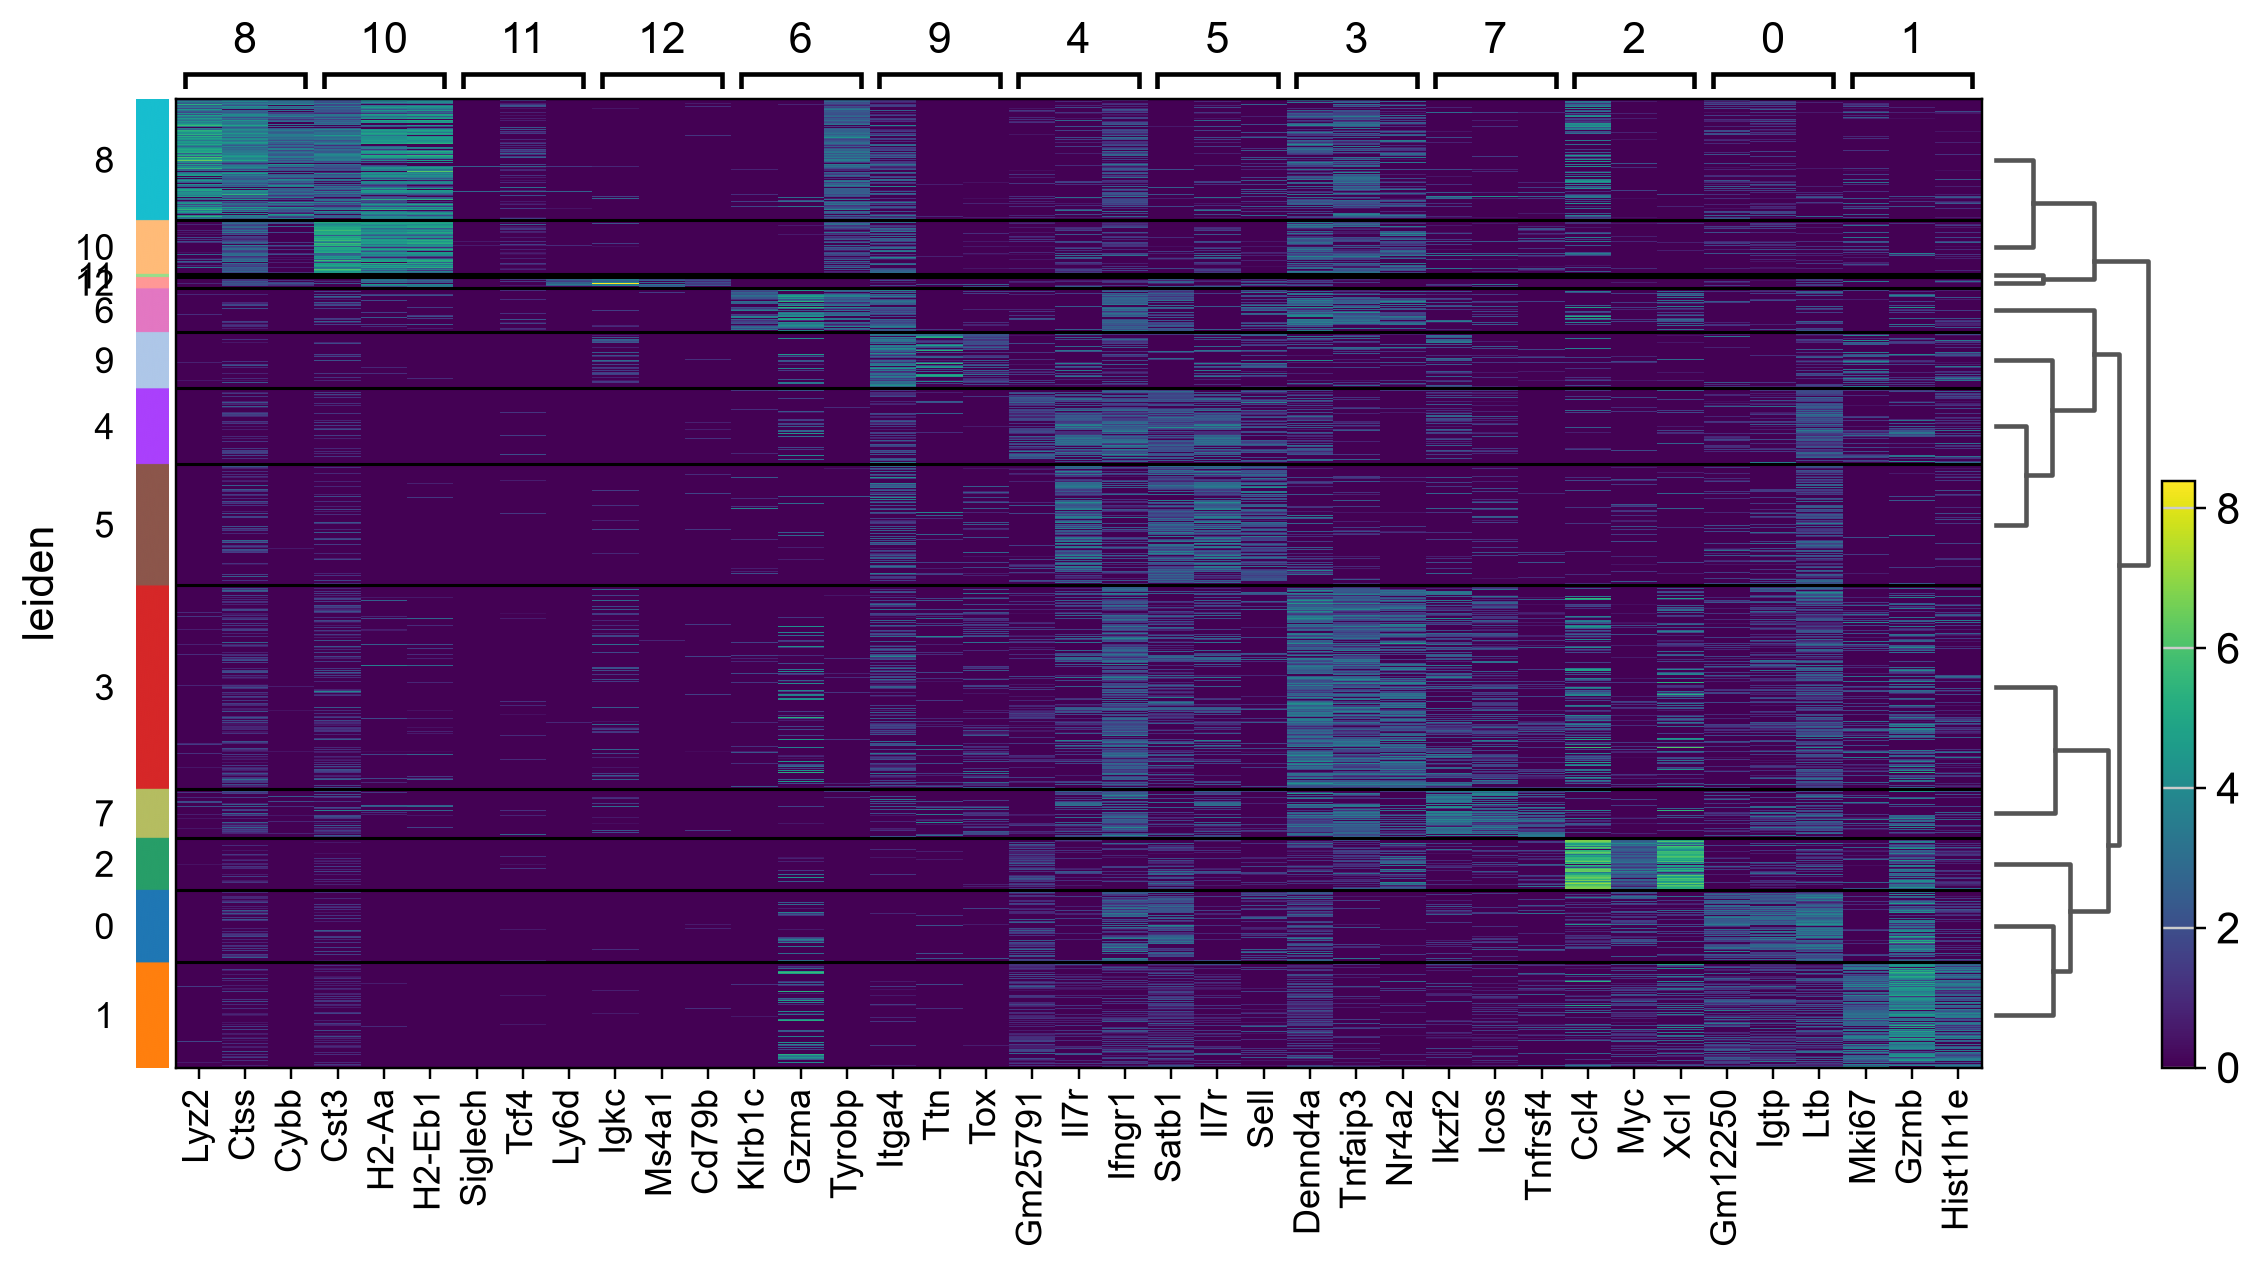

In [32]:
sc.pl.rank_genes_groups_heatmap(
    adata,
    n_genes=3,
    groupby="leiden",
    show_gene_labels=True,
    figsize=(12, 6)
)

3. Volcano plot for cluster 0

The horizontal axis is log2 fold change; the vertical axis is −log10 adjusted p-value. Points farther right are more highly expressed in cluster 0; points higher up have stronger statistical evidence. The red points satisfy both illustrative thresholds. Extremely small adjusted p-values are clipped to avoid infinite plotting values.

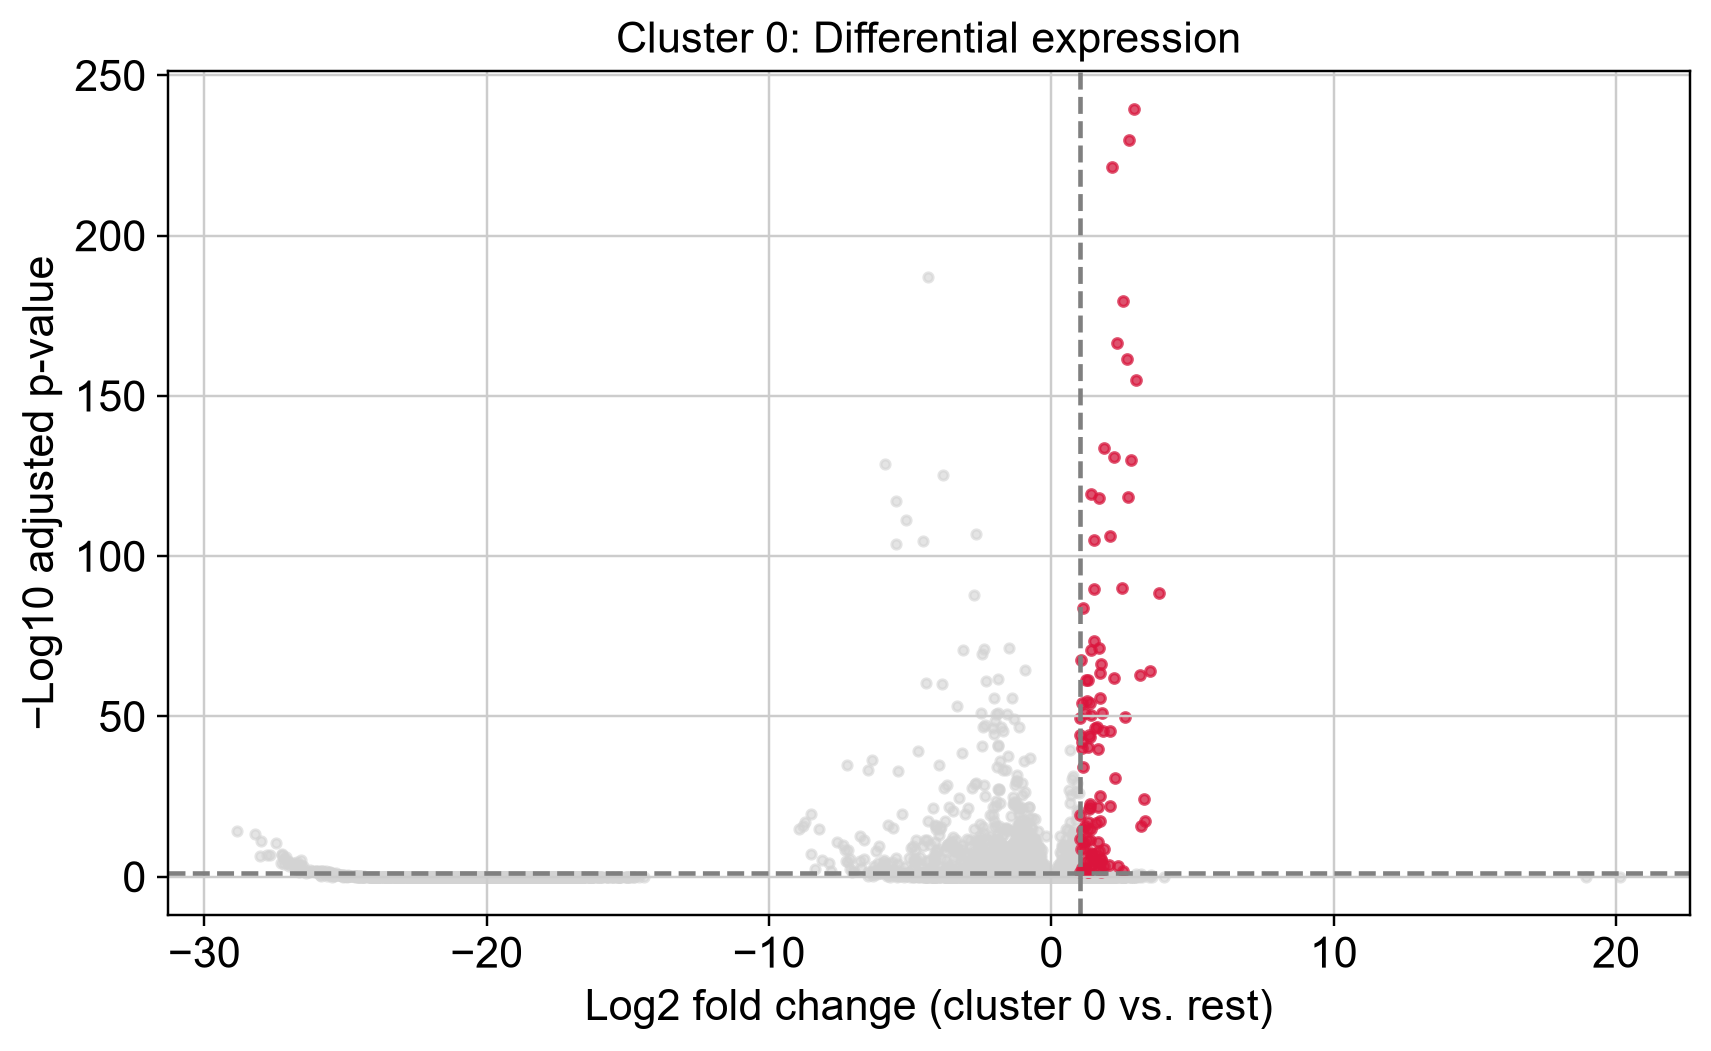

In [33]:
x = deg["logfoldchanges"]
y = -np.log10(deg["pvals_adj"].clip(lower=1e-300))
hit = (deg["pvals_adj"] < 0.05) & (x > 1)

plt.figure(figsize=(8, 5))
plt.scatter(x, y, s=9, c="lightgray", alpha=0.6)
plt.scatter(x[hit], y[hit], s=10, c="crimson", alpha=0.7)
plt.axvline(1, color="gray", linestyle="--")
plt.axhline(-np.log10(0.05), color="gray", linestyle="--")
plt.xlabel("Log2 fold change (cluster 0 vs. rest)")
plt.ylabel("−Log10 adjusted p-value")
plt.title("Cluster 0: Differential expression")
plt.tight_layout()
plt.show()